# Certifiable Trajectory Optimization using SDP relaxations with a Bernstein polynomial basis

An executable introduction to Graesdal, Amice, Parrilo & Tedrake,
[Semidefinite Relaxations for Collision-Free Motion Planning](https://arxiv.org/abs/2606.14063).


In [ ]:
using Pkg; Pkg.activate("."); Pkg.instantiate()
using LinearAlgebra
using JuMP, Hypatia
ENV["GKSwstype"] = "100"
using Plots

### 1.1 Basis and curve — equation (25)

$$B_i^d(s)=\binom di s^i(1-s)^{d-i},\qquad
b_d(s)=[B_0^d(s),\ldots,B_d^d(s)]^\top,\qquad \gamma(s)=\Gamma b_d(s).$$

`B(d,i,s)` uses the paper's **zero-based polynomial index** $i=0,\ldots,d$.
Julia arrays remain one-based: column `i+1` of `Γ` is control point $P_i$.
The columns of `Γ` are vectors in the physical configuration space; there is still
only one polynomial variable, $s$.


In [ ]:
function B(d::Integer, i::Integer, s)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    0 <= i <= d || throw(ArgumentError("require 0 ≤ i ≤ d"))
    return binomial(d, i) * s^i * (1 - s)^(d - i)
end

function b(d::Integer, s)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    return [B(d, i, s) for i in 0:d]
end

γ(Γ, s) = Γ * b(size(Γ, 2) - 1, s)

γ (generic function with 1 method)

### 1.2 Differences and derivatives — equation (28)

$D_d$ has $d+1$ rows and $d$ columns, with $-1$ on the diagonal and $+1$
immediately below it. Thus $\Gamma D_d$ contains adjacent control-point differences.

$$D_d^{(k)}=D_dD_{d-1}\cdots D_{d-k+1},\qquad
\gamma^{(k)}(s)=\frac{d!}{(d-k)!}\Gamma D_d^{(k)}b_{d-k}(s).$$

The difference matrix **does not include** the factorial factor. `Dk(d,0)` is the
identity, so `γk(Γ,s,0)` returns position. The range `d:-1:(d-k+1)` counts downward
through exactly $k$ matrices. These functions deliberately require $k\leq d$;
derivatives of higher order vanish but are not represented by a negative-degree basis.


In [3]:
function D(d::Integer)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    return diagm(d + 1, d, 0 => -ones(d), -1 => ones(d))
end

function Dk(d::Integer, k::Integer)
    0 <= k <= d || throw(ArgumentError("require 0 ≤ k ≤ d"))
    result = Matrix{Float64}(I, d + 1, d + 1)
    for j in d:-1:(d - k + 1)
        result = result * D(j)
    end
    return result
end

function derivative_factor(d::Integer, k::Integer)
    0 <= k <= d || throw(ArgumentError("require 0 ≤ k ≤ d"))
    return prod(Float64(j) for j in (d - k + 1):d; init=1.0)
end

function γk(Γ, s, k::Integer)
    d = size(Γ, 2) - 1
    return derivative_factor(d, k) * Γ * Dk(d, k) * b(d - k, s)
end


γk (generic function with 1 method)

### 1.3 Gram matrices and integrated costs — equations (29)–(30)

$$[G_d]_{ij}=\int_0^1B_i^d(s)B_j^d(s)\,ds
=\frac{\binom di\binom dj}{(2d+1)\binom{2d}{i+j}},$$

$$G_d^{(k)}=\left(\frac{d!}{(d-k)!}\right)^2
D_d^{(k)}G_{d-k}(D_d^{(k)})^\top,\qquad
J_k(\Gamma)=\operatorname{tr}(G_d^{(k)}\Gamma^\top\Gamma).$$

`G(d)` and `Gk(d,k)` are **known cost matrices**, not SDP decision variables.
They integrate the basis products once, so evaluating a cost needs no quadrature.
The code uses exact integer ratios before converting Gram entries to Float64.
This is an introductory numerical implementation; high-degree conditioning still matters.


In [4]:
function G(d::Integer)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    return [Float64((binomial(big(d), i) * binomial(big(d), j)) //
                    ((2d + 1) * binomial(big(2d), i + j)))
            for i in 0:d, j in 0:d]
end

function Gk(d::Integer, k::Integer)
    differences = Dk(d, k)
    return derivative_factor(d, k)^2 * differences * G(d - k) * differences'
end

curve_cost(Γ, k::Integer) = tr(Gk(size(Γ, 2) - 1, k) * Γ' * Γ)


curve_cost (generic function with 1 method)

### 1.4 Coefficient maps for collision certificates — equations (32)–(33)

For a $(d+1)\times(d+1)$ matrix $M$, $S_d(M)$ returns the degree-$2d$ Bernstein
coefficients of $b_d(s)^\top M b_d(s)$:

$$[S_d(M)]_j=\sum_{i+\ell=j}
\frac{\binom di\binom d\ell}{\binom{2d}j}M_{i\ell}.$$

For a $d\times d$ matrix $N$, $T_d(N)$ returns the coefficients of
$s(1-s)b_{d-1}(s)^\top N b_{d-1}(s)$:

$$[T_d(N)]_j=\begin{cases}
\dfrac{j(2d-j)}{2d(2d-1)}[S_{d-1}(N)]_{j-1},&1\leq j\leq2d-1,\\
0,&j=0,2d.
\end{cases}$$

These maps work on numerical matrices **or JuMP affine expressions**. We sum both
off-diagonal entries, as required by the quadratic form. The matrix $N$ is empty
when $d=0$, in which case its contribution is zero.


In [5]:
function S(d::Integer, M)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    size(M) == (d + 1, d + 1) || throw(DimensionMismatch("S_d needs a (d+1)×(d+1) matrix"))
    return [sum(Float64((binomial(big(d), i) * binomial(big(d), j - i)) //
                        binomial(big(2d), j)) * M[i + 1, j - i + 1]
                for i in max(0, j - d):min(d, j))
            for j in 0:2d]
end

function T(d::Integer, N)
    d >= 0 || throw(ArgumentError("d must be nonnegative"))
    size(N) == (d, d) || throw(DimensionMismatch("T_d needs a d×d matrix"))
    d == 0 && return [0.0]
    lower = S(d - 1, N)
    return [j == 0 || j == 2d ? zero(lower[1]) :
            (j * (2d - j) / (2d * (2d - 1))) * lower[j]
            for j in 0:2d]
end


T (generic function with 1 method)

### 1.5 From a sphere to an SOS identity — Lemma 2 and Appendix D.2

Let $c$ be the obstacle center, $r$ its radius, and $e=(1,\ldots,1)^\top$.
Since $e^\top b_d(s)=1$, the clearance polynomial is

$$p(s)=\|\Gamma b_d(s)-c\|^2-r^2.$$

Writing $X=\Gamma^\top\Gamma$, its coefficient vector is

$$S_d\!\left(X-(\Gamma^\top c)e^\top-e(c^\top\Gamma)
 +(c^\top c-r^2)ee^\top\right).$$

Nonnegativity on the entire interval has an exact univariate representation

$$p(s)=b_d(s)^\top Q_0b_d(s)+s(1-s)b_{d-1}(s)^\top Q_1b_{d-1}(s),
\quad Q_0,Q_1\succeq0.$$

Matching Bernstein coefficients gives $p_{\rm coeff}=S_d(Q_0)+T_d(Q_1)$.
For a **fixed curve**, this is a convex SDP feasibility problem. Optimizing the
curve still requires relaxing the nonconvex equation $X=\Gamma^\top\Gamma$.


In [6]:
function collision_coefficients(Γ, X, center, radius)
    d = size(Γ, 2) - 1
    e = ones(d + 1)
    M = X - (Γ' * center) * e' - e * (center' * Γ) +
        (dot(center, center) - radius^2) * (e * e')
    return S(d, M)
end

function collision_certificate!(model, Γ, X, center, radius)
    d = size(Γ, 2) - 1
    d >= 1 || throw(ArgumentError("this SDP helper requires d ≥ 1"))
    Q0 = @variable(model, [1:(d + 1), 1:(d + 1)], PSD)
    Q1 = @variable(model, [1:d, 1:d], PSD)
    residual = collision_coefficients(Γ, X, center, radius) - S(d, Q0) - T(d, Q1)
    matching = @constraint(model, residual .== 0)
    return (; Q0, Q1, residual, matching)
end


collision_certificate! (generic function with 1 method)

### 1.6 Check the formulas before solving an optimization problem

The checks below compare the derivative formulas with an independent monomial
expansion, integrate squared derivatives by their monomial coefficients, and evaluate
the $S_d$ and $T_d$ identities. They exercise several degrees and all $k=0,\ldots,d$,
not just the quadratic example. Samples here check algebraic implementations; they
are not used to impose collision constraints.


In [7]:
function monomial_expansion(Γ)
    d = size(Γ, 2) - 1
    coefficients = zeros(size(Γ, 1), d + 1)
    for i in 0:d, j in 0:(d - i)
        coefficients[:, i + j + 1] += Γ[:, i + 1] *
            binomial(d, i) * binomial(d - i, j) * (-1)^j
    end
    return coefficients
end

@testset "Appendix D identities" begin
    for d in 0:5
        Γcheck = reshape(sin.(1:(2 * (d + 1))), 2, d + 1)
        C = monomial_expansion(Γcheck)
        M = reshape(cos.(1:(d + 1)^2), d + 1, d + 1)
        M = M + M'
        for s in (0.0, 0.17, 0.5, 0.83, 1.0)
            @test sum(b(d, s)) ≈ 1
            @test dot(S(d, M), b(2d, s)) ≈ dot(b(d, s), M * b(d, s)) atol=1e-12
        end
        for k in 0:d
            Ck = hcat([C[:, j + 1] * derivative_factor(j, k) for j in k:d]...)
            exact_integral = sum(dot(Ck[:, i + 1], Ck[:, j + 1]) / (i + j + 1)
                                 for i in 0:(d - k), j in 0:(d - k))
            @test curve_cost(Γcheck, k) ≈ exact_integral atol=1e-7 rtol=1e-9
            for s in (0.0, 0.31, 1.0)
                @test γk(Γcheck, s, k) ≈ Ck * [s^j for j in 0:(d - k)] atol=1e-10
            end
        end
        if d >= 1
            N = reshape(sin.(1:d^2), d, d)
            N = N + N'
            for s in (0.0, 0.29, 0.5, 1.0)
                @test dot(T(d, N), b(2d, s)) ≈
                    s * (1 - s) * dot(b(d - 1, s), N * b(d - 1, s)) atol=1e-12
            end
        end
    end
    @test G(0) == ones(1, 1)
    @test T(0, zeros(0, 0)) == [0.0]
    @test_throws ArgumentError Dk(2, 3)
    @test_throws ArgumentError b(-1, 0.5)
    @test_throws DimensionMismatch S(2, zeros(2, 2))
end
nothing


Test Summary:         | Pass  

Total  Time
Appendix D identities |  169    169  1.0s


## 2. Worked example: one quadratic curve around one circle

We choose $n=2$, $d=2$, and $k=1$. The start is $(-2,0)$, the goal is $(2,0)$,
and the obstacle is the radius-$1/2$ circle centered at the origin. The endpoint
positions are fixed; endpoint velocities are free. Only the middle control point moves:

$$\Gamma=\begin{bmatrix}-2&a&2\\0&h&0\end{bmatrix},\qquad
\gamma(s)=\begin{bmatrix}-2+4s+2as(1-s)\\2hs(1-s)\end{bmatrix}.$$

The first problem is Graesdal's normalized squared-velocity cost, not minimum time:

$$\min_{a,h}\int_0^1\|\gamma'(s)\|^2ds
\quad\text{subject to}\quad \|\gamma(s)\|^2-1/4\geq0\ \ \forall s\in[0,1].$$


In [8]:
n, d, k = 2, 2, 1
start = [-2.0, 0.0]
goal = [2.0, 0.0]
center = [0.0, 0.0]
radius = 0.5
Γexample = hcat(start, [0.0, 1.0], goal)

display((D2=D(d), G2=G(d), G2_1=Gk(d, k)))
display((position=γ(Γexample, 0.5),
         velocity=γk(Γexample, 0.5, 1),
         acceleration=γk(Γexample, 0.5, 2),
         cost=curve_cost(Γexample, k)))


(D2 = [-1.0 0.0; 1.0 -1.0; 0.0 1.0], G2 = [0.2 0.1 0.03333333333333333; 0.1 0.13333333333333333 0.1; 0.03333333333333333 0.1 0.2], G2_1 = [1.3333333333333333 -0.6666666666666666 -0.6666666666666666; -0.6666666666666666 1.3333333333333333 -0.6666666666666666; -0.6666666666666666 -0.6666666666666666 1.3333333333333333])

(position = [0.0, 0.5], velocity = [4.0, 0.0], acceleration = [0.0, -4.0], cost = 17.333333333333336)

### 2.1 See the basis, control points, and curve

At $s=1/2$, the three basis weights are $(1/4,1/2,1/4)$.
Thus the curve passes through $(0,1/2)$, even though its middle control point is $(0,1)$.
Control points shape the curve; they are not generally waypoints.


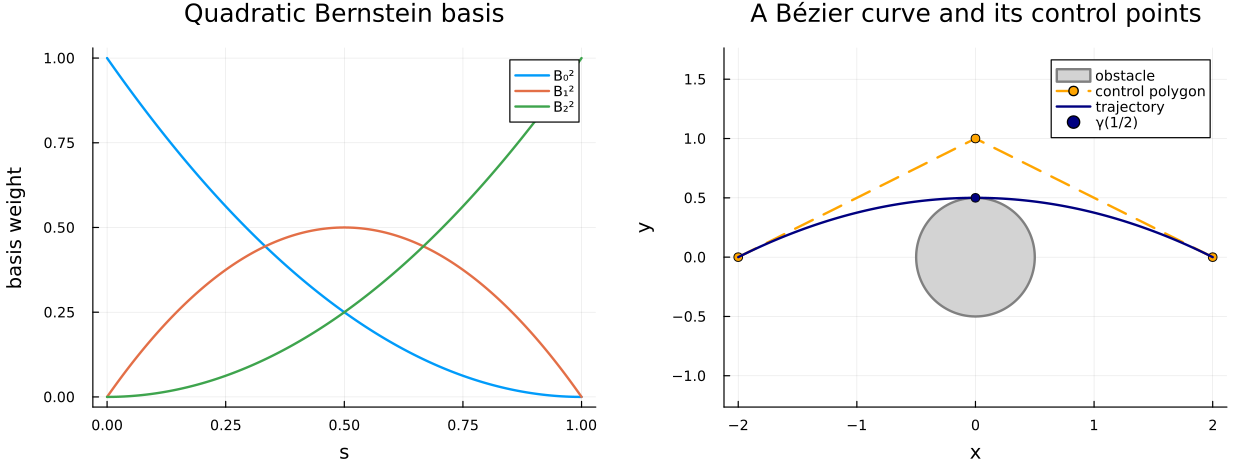

In [9]:
ss = range(0, 1; length=401)
θ = range(0, 2π; length=201)
circle = Shape(radius .* cos.(θ), radius .* sin.(θ))
points = hcat([γ(Γexample, s) for s in ss]...)

p_basis = plot(ss, hcat([b(d, s) for s in ss]...)',
    label=["B₀²" "B₁²" "B₂²"], xlabel="s", ylabel="basis weight",
    title="Quadratic Bernstein basis")
p_curve = plot(circle; color=:lightgray, linecolor=:gray, label="obstacle",
    aspect_ratio=:equal, xlabel="x", ylabel="y", title="A Bézier curve and its control points")
plot!(p_curve, Γexample[1, :], Γexample[2, :]; linestyle=:dash, marker=:circle,
    color=:orange, label="control polygon")
plot!(p_curve, points[1, :], points[2, :]; color=:navy, label="trajectory")
scatter!(p_curve, [0.0], [0.5]; color=:navy, label="γ(1/2)")
plot(p_basis, p_curve; layout=(1, 2), size=(1050, 390))


### 2.2 Know the answer before trusting the solver

Direct integration gives $J_1=16+\frac43(a^2+h^2)$. At $s=1/2$,
$\gamma(1/2)=(a/2,h/2)$, so every feasible curve obeys $a^2+h^2\geq1$.
Therefore **$J_1\geq52/3$**.

Both $(a,h)=(0,1)$ and $(0,-1)$ achieve that bound. Their continuous feasibility
has a simple exact certificate. With $u=2s-1$,

$$\|\gamma(s)\|^2-1/4=\frac72u^2+\frac14u^4\geq0.$$

This proves the optimum within this single-quadratic family. It does not prove
optimality over arbitrary polynomial degrees, segment counts, or all continuous paths.


In [10]:
J_exact = 52 / 3
u_coeff = [-1.0, 0.0, 1.0]       # u = 2s-1 in the degree-2 Bernstein basis
u2_coeff = [1.0, -1.0, 1.0]      # u² in the same basis
Q0_exact = (7 / 2) * (u_coeff * u_coeff') + (1 / 4) * (u2_coeff * u2_coeff')
Q1_exact = zeros(2, 2)

@test curve_cost(Γexample, k) ≈ J_exact
@test collision_coefficients(Γexample, Γexample' * Γexample, center, radius) ≈
    S(d, Q0_exact) + T(d, Q1_exact)
@test eigmin(Symmetric(Q0_exact)) >= -1e-12
@printf("Analytic optimum: J = 52/3 = %.10f\n", J_exact)
println("An explicit PSD Gram matrix certifies clearance for every s, not only samples.")


Analytic optimum: J = 52/3 = 17.3333333333
An explicit PSD Gram matrix certifies clearance for every s, not only samples.

### 2.3 The SDP lift and endpoint elimination — Section V.B–C

The nonconvex object is $\Gamma^\top\Gamma$. Graesdal introduces $X$ and relaxes
$X=\Gamma^\top\Gamma$ to $X\succeq\Gamma^\top\Gamma$.

Here the endpoint columns are fixed. Let $w$ replace $a^2+h^2$. Eliminating the fixed
columns and enforcing their implied products gives

$$X=\begin{bmatrix}4&-2a&-4\\-2a&w&2a\\-4&2a&4\end{bmatrix},\qquad
\begin{bmatrix}1&0&a\\0&1&h\\a&h&w\end{bmatrix}\succeq0.$$

The smaller PSD constraint means $w\geq a^2+h^2$. This is the paper's facial-reduction
idea specialized to one free control point; it also satisfies the endpoint tightening
constraints $XA=\Gamma^\top B$ automatically.

The objective becomes $\operatorname{tr}(G_2^{(1)}X)=16+4w/3$.
Collision avoidance is imposed by coefficient matching with $Q_0,Q_1\succeq0$.
The following builder is deliberately **specific to this quadratic example**.


In [11]:
function quadratic_relaxation(; minimum_time=false, vmax=1.0)
    model = Model(() -> Hypatia.Optimizer(verbose=false,
        tol_feas=1e-8, tol_rel_opt=1e-8, tol_abs_opt=1e-8))
    @variable(model, a)
    @variable(model, h)
    @variable(model, w)

    Γ = [-2.0 a 2.0; 0.0 h 0.0]
    X = [4.0 -2a -4.0; -2a w 2a; -4.0 2a 4.0]
    lifted_block = [1.0 0.0 a; 0.0 1.0 h; a h w]
    @constraint(model, lifted_block in PSDCone())
    certificate = collision_certificate!(model, Γ, X, [0.0, 0.0], 0.5)

    τ = nothing
    if minimum_time
        vmax > 0 || throw(ArgumentError("vmax must be positive"))
        τ = @variable(model, lower_bound=0.0, base_name="squared_duration")
        @constraint(model, 4 * (4 + 4a + w) <= vmax^2 * τ)
        @constraint(model, 4 * (4 - 4a + w) <= vmax^2 * τ)
        @objective(model, Min, τ)
    else
        @objective(model, Min, sum(Gk(2, 1) .* X))
    end
    return (; model, a, h, w, Γ, X, lifted_block, certificate, τ)
end

relaxation = quadratic_relaxation()
optimize!(relaxation.model)
solution_summary(relaxation.model)


solution_summary(; result = 1, verbose = false)
├ solver_name          : Hypatia
├ Termination
│ ├ termination_status : OPTIMAL
│ ├ result_count       : 1
│ └ raw_status         : Optimal
├ Solution (result = 1)
│ ├ primal_status        : FEASIBLE_POINT
│ ├ dual_status          : FEASIBLE_POINT
│ ├ objective_value      : 1.73333e+01
│ └ dual_objective_value : 1.73333e+01
└ Work counters
  ├ solve_time (sec)   : 3.41248e+00
  └ barrier_iterations : 14

### 2.4 Inspect the solver, bound, and certificate residuals

The primal objective estimates the optimum of the **SDP**. The dual objective provides
its numerical lower-bound estimate for the original minimization problem. Neither
solver output alone is an exact-arithmetic proof. We check PSD and coefficient residuals,
then compare with the independent analytic proof above.


In [12]:
model = relaxation.model
@assert termination_status(model) == JuMP.MOI.OPTIMAL
@assert primal_status(model) == JuMP.MOI.FEASIBLE_POINT
@assert dual_status(model) == JuMP.MOI.FEASIBLE_POINT

Γhat = value.(relaxation.Γ)
Xhat = value.(relaxation.X)
Q0hat = value.(relaxation.certificate.Q0)
Q1hat = value.(relaxation.certificate.Q1)
L_numeric = dual_objective_value(model)
U_exact = curve_cost(Γexample, k)
coefficient_residual = norm(value.(relaxation.certificate.residual), Inf)
psd_residuals = (lift=eigmin(Symmetric(value.(relaxation.lifted_block))),
                 Q0=eigmin(Symmetric(Q0hat)), Q1=eigmin(Symmetric(Q1hat)))

@printf("SDP primal objective:          %.10f\n", objective_value(model))
@printf("SDP dual lower-bound estimate: %.10f\n", L_numeric)
@printf("Verified candidate cost:       %.10f\n", U_exact)
@printf("Candidate minus dual estimate: %.3e\n", U_exact - L_numeric)
@printf("Coefficient residual (∞ norm): %.3e\n", coefficient_residual)
display(psd_residuals)
display((middle_control_point=Γhat[:, 2], w=value(relaxation.w)))

@test objective_value(model) ≈ J_exact atol=2e-6
@test L_numeric ≈ J_exact atol=2e-6
@test coefficient_residual < 2e-6
@test minimum(psd_residuals) > -2e-6


SDP primal objective:          17.3333333382
SDP dual lower-bound estimate: 17.3333333191


Verified candidate cost:       17.3333333333
Candidate minus dual estimate: 1.426e-08
Coefficient residual (∞ norm): 5.551e-16


(lift = 0.980871773066745, Q0 = 7.563834599970033e-10, Q1 = 5.049920207368459e-9)

(middle_control_point = [2.7581751417999526e-10, -0.019128228763023038], w = 1.0000000036595362)

Test Passed

### 2.5 An exact objective bound does not guarantee a feasible returned curve

This symmetric problem has two optimal physical paths. The SDP can return $a\approx0$,
$h\approx0$, $w\approx1$. Its coefficient curve goes through the obstacle, while
the extra slack in $X-\Gamma^\top\Gamma$ makes the **lifted** clearance nonnegative.

Thus **objective-value tightness** and **recovery of a physical curve** are different.
For this example, we can recover the upper/lower branches using its geometry:
$a=0$, $h=\pm\sqrt{w}$. The numerical control point should be close to $(0,\pm1)$;
we use the analytically verified exact points for our final feasible candidates.
This example-specific recovery is not a general rounding algorithm.


(slack_eigenvalues = [0.0, 0.0, 0.9996341145239257], curve_midpoint = [1.3790873998331676e-10, -0.009564114381511519], midpoint_clearance = -0.24990852771609737, recovered_upper_middle = [0.0, 1.0000000018297681])

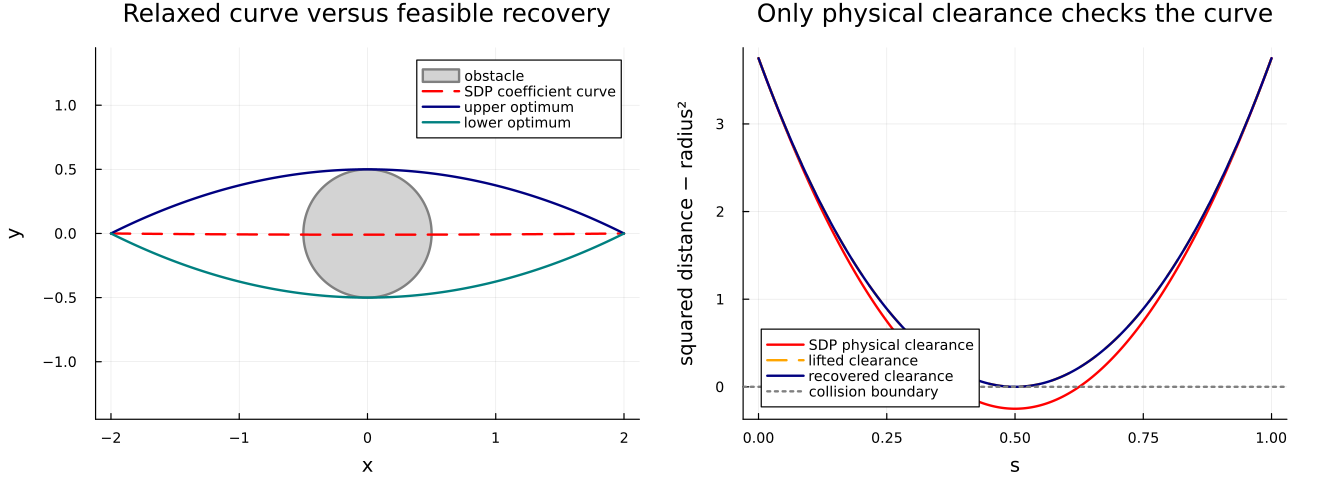

In [13]:
slack = Symmetric(Xhat - Γhat' * Γhat)
display((slack_eigenvalues=eigvals(slack),
         curve_midpoint=γ(Γhat, 0.5),
         midpoint_clearance=sum(abs2, γ(Γhat, 0.5)) - radius^2,
         recovered_upper_middle=[0.0, sqrt(max(0.0, value(relaxation.w))) ]))

Γupper = [-2.0 0.0 2.0; 0.0 1.0 0.0]
Γlower = [-2.0 0.0 2.0; 0.0 -1.0 0.0]
lifted_coefficients = collision_coefficients(Γhat, Xhat, center, radius)
clearance_physical = [sum(abs2, γ(Γhat, s) - center) - radius^2 for s in ss]
clearance_lifted = [dot(lifted_coefficients, b(2d, s)) for s in ss]
clearance_upper = [sum(abs2, γ(Γupper, s) - center) - radius^2 for s in ss]

p_paths = plot(circle; color=:lightgray, linecolor=:gray, label="obstacle",
    aspect_ratio=:equal, xlabel="x", ylabel="y", title="Relaxed curve versus feasible recovery")
for (Γplot, name, style, color) in ((Γhat, "SDP coefficient curve", :dash, :red),
                                  (Γupper, "upper optimum", :solid, :navy),
                                  (Γlower, "lower optimum", :solid, :teal))
    xy = hcat([γ(Γplot, s) for s in ss]...)
    plot!(p_paths, xy[1, :], xy[2, :]; label=name, linestyle=style, color)
end
p_clearance = plot(ss, clearance_physical; label="SDP physical clearance", color=:red,
    xlabel="s", ylabel="squared distance − radius²", title="Only physical clearance checks the curve")
plot!(p_clearance, ss, clearance_lifted; label="lifted clearance", linestyle=:dash, color=:orange)
plot!(p_clearance, ss, clearance_upper; label="recovered clearance", color=:navy)
hline!(p_clearance, [0.0]; color=:gray, linestyle=:dot, label="collision boundary")
plot(p_paths, p_clearance; layout=(1, 2), size=(1100, 400))


## 3. Extension toward Von Moll: minimum time with a speed limit

This section is a derived extension, not a result claimed by Graesdal's paper.
We retain the same static obstacle and free endpoint velocities, and omit heading,
turn-rate constraints, minimum speed, and distributional robustness.

Let physical time be $t=Ts$ and $q(t)=\gamma(t/T)$. Physical velocity is
$\dot q=\gamma'/T$. Introduce $\tau=T^2$; minimizing $\tau$ is equivalent to
minimizing $T>0$.

For a quadratic curve, $\gamma'$ is a linear Bézier curve. Its norm attains its
maximum at an endpoint, so the two endpoint inequalities are **necessary and
sufficient** for the speed bound over the entire segment:

$$4((a+2)^2+h^2)\leq v_{\max}^2\tau,\qquad
4((2-a)^2+h^2)\leq v_{\max}^2\tau.$$

Replace $a^2+h^2$ with $w$ to obtain the affine inequalities already present in the
example builder. Collision avoidance uses the same SDP certificate.
For $v_{\max}=1$, the known optimum is $\tau^*=20$, $T^*=\sqrt{20}$.
Indeed $\tau\geq16+4(a^2+h^2)+16|a|\geq20$, and $(a,h)=(0,\pm1)$ attains it.


SDP squared-duration objective: 19.9999998998
SDP squared-duration dual:      19.9999999301
Duration lower-bound estimate:  4.4721359472
Verified candidate duration:    4.4721359550
Maximum physical speed:         1.0000000000


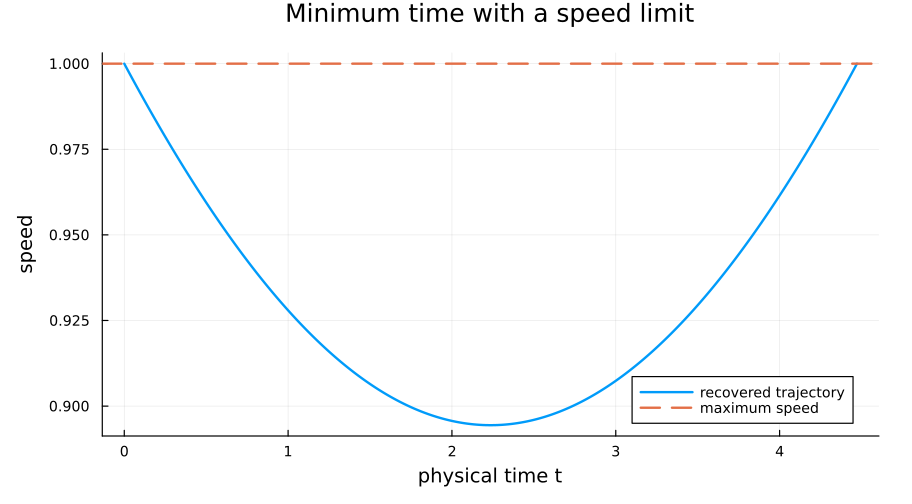

In [14]:
vmax = 1.0
time_relaxation = quadratic_relaxation(minimum_time=true, vmax=vmax)
optimize!(time_relaxation.model)
@assert termination_status(time_relaxation.model) == JuMP.MOI.OPTIMAL
@assert dual_status(time_relaxation.model) == JuMP.MOI.FEASIBLE_POINT

τ_sdp = objective_value(time_relaxation.model)
τ_dual = dual_objective_value(time_relaxation.model)
duration = sqrt(20.0) / vmax
physical_speed = [norm(γk(Γupper, s, 1)) / duration for s in ss]
endpoint_speed = maximum(norm(γk(Γupper, s, 1)) / duration for s in (0.0, 1.0))

@printf("SDP squared-duration objective: %.10f\n", τ_sdp)
@printf("SDP squared-duration dual:      %.10f\n", τ_dual)
@printf("Duration lower-bound estimate:  %.10f\n", sqrt(max(0.0, τ_dual)))
@printf("Verified candidate duration:    %.10f\n", duration)
@printf("Maximum physical speed:         %.10f\n", endpoint_speed)

@test τ_sdp ≈ 20 / vmax^2 atol=2e-6
@test τ_dual ≈ 20 / vmax^2 atol=2e-6
@test endpoint_speed <= vmax + 1e-12
@test norm(value.(time_relaxation.certificate.residual), Inf) < 2e-6
@test eigmin(Symmetric(value.(time_relaxation.lifted_block))) > -2e-6
@test eigmin(Symmetric(value.(time_relaxation.certificate.Q0))) > -2e-6
@test eigmin(Symmetric(value.(time_relaxation.certificate.Q1))) > -2e-6

p_speed = plot(duration .* ss, physical_speed; xlabel="physical time t", ylabel="speed",
    label="recovered trajectory", title="Minimum time with a speed limit")
hline!(p_speed, [vmax]; linestyle=:dash, label="maximum speed")
p_speed


## 4. What this notebook establishes

- Appendix D's basis, differentiation, Gram matrices, and coefficient maps have executable checks.
- The obstacle constraint is imposed over the **whole interval**, not at sampled points.
- Hypatia solves the lifted convex problem, and its numerical residuals are reported.
- The example's exact lower bound and explicit feasible curve independently prove its global
  optimum within the chosen quadratic family. Floating-point SDP output alone is not a formal certificate.
- The symmetric example distinguishes a tight objective bound from successful curve recovery.
- A squared-duration variable extends this particular example to minimum time with a speed limit.

Natural experiments: change the radius, break the obstacle symmetry, or raise the curve degree.
The general functions support other degrees; the hard-coded example builder and analytic
recovery must be updated accordingly. For a strictly positive clearance margin, increase the
obstacle radius before solving. Changing the basis never by itself makes obstacle avoidance convex.

**References**

- [Graesdal et al., arXiv:2606.14063](https://arxiv.org/abs/2606.14063), Appendix D,
  Lemma 2, Sections V.B–C and VI.
- [JuMP semidefinite constraints](https://jump.dev/JuMP.jl/stable/manual/constraints/#Semidefinite-constraints).
- [Hypatia.jl](https://github.com/jump-dev/Hypatia.jl).
